In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Exact path of your dataset
file_path = '/content/drive/MyDrive/CODE_ALPHA_INTERNSHIP/Unemployment in India.csv'

# Read CSV file
df = pd.read_csv(file_path)

# Display first five rows
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [ ]:
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Replace empty strings with NaN
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Convert numerical columns
numeric_cols = [
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Convert Date column
df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

# Remove rows with missing essential values
df.dropna(subset=[
    'Region',
    'Date',
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)',
    'Area'
], inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Sort dataset by date
df.sort_values('Date', inplace=True)
df.reset_index(drop=True, inplace=True)

print("\nDataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

display(df.head())

Missing values before cleaning:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Dataset shape after cleaning: (740, 7)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


In [ ]:
#Basic statistical analysis
unemployment_col = 'Estimated Unemployment Rate (%)'

print("Overall Average Unemployment Rate:",
      round(df[unemployment_col].mean(), 2), "%")

print("Maximum Unemployment Rate:",
      round(df[unemployment_col].max(), 2), "%")

print("Minimum Unemployment Rate:",
      round(df[unemployment_col].min(), 2), "%")

print("Standard Deviation:",
      round(df[unemployment_col].std(), 2))

print("\nStatistical Summary:")
display(df[numeric_cols].describe())

Overall Average Unemployment Rate: 11.79 %
Maximum Unemployment Rate: 76.74 %
Minimum Unemployment Rate: 0.0 %
Standard Deviation: 10.72

Statistical Summary:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


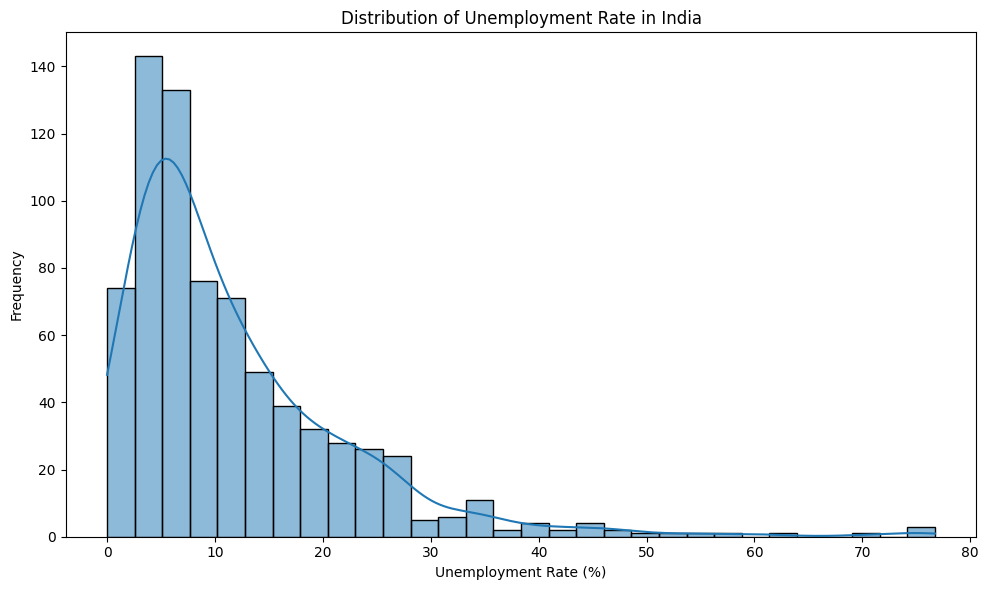

In [ ]:
#Overall unemployment distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    df[unemployment_col],
    bins=30,
    kde=True
)

plt.title('Distribution of Unemployment Rate in India')
plt.xlabel('Unemployment Rate (%)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

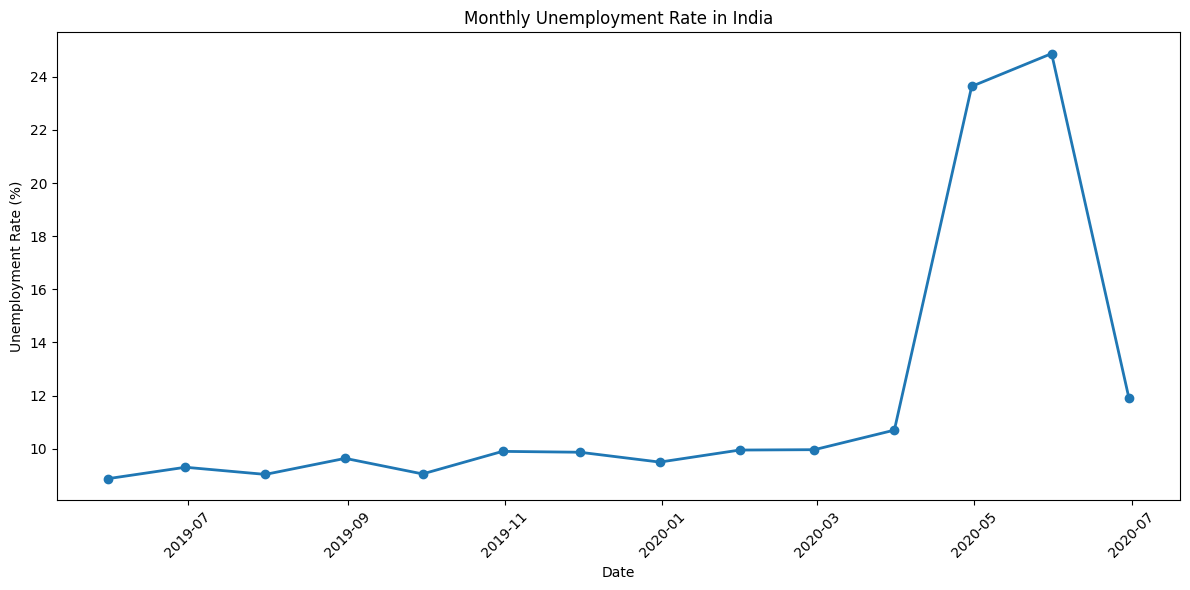

,Date,Estimated Unemployment Rate (%)
0,2019-05-31,8.874259
1,2019-06-30,9.303333
2,2019-07-31,9.033889
3,2019-08-31,9.637925
4,2019-09-30,9.051731
5,2019-10-31,9.900909
6,2019-11-30,9.868364
7,2019-12-31,9.497358
8,2020-01-31,9.950755
9,2020-02-29,9.964717


In [ ]:
#Overall unemployment trend
monthly_unemployment = (
    df.groupby('Date')[unemployment_col]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment['Date'],
    monthly_unemployment[unemployment_col],
    marker='o',
    linewidth=2
)

plt.title('Monthly Unemployment Rate in India')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_unemployment)

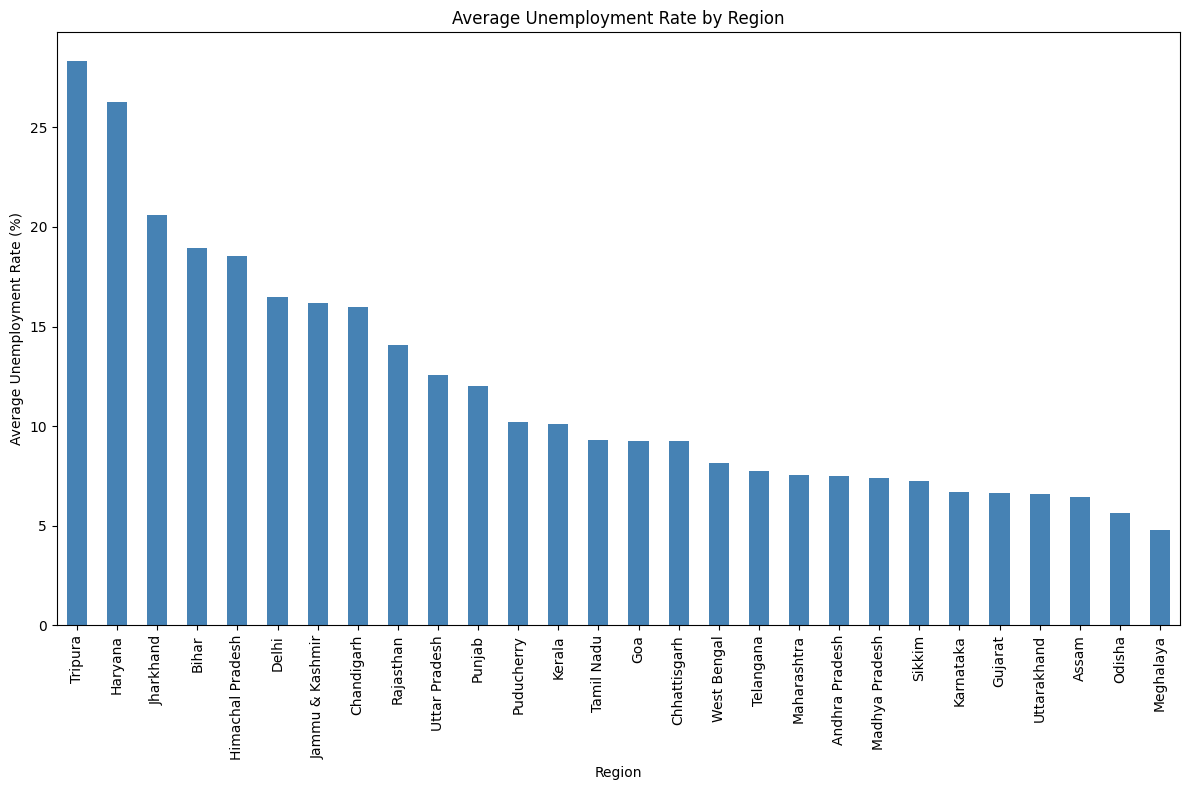

Top 10 regions with highest average unemployment:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


Top 10 regions with lowest average unemployment:


,Estimated Unemployment Rate (%)
Region,
Maharashtra,7.557500
Andhra Pradesh,7.477143
Madhya Pradesh,7.406429
Sikkim,7.249412
Karnataka,6.676071
Gujarat,6.663929
Uttarakhand,6.582963
Assam,6.428077
Odisha,5.657857


In [ ]:
#State-wise unemployment analysis
state_unemployment = (
    df.groupby('Region')[unemployment_col]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

state_unemployment.plot(
    kind='bar',
    color='steelblue'
)

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Top 10 regions with highest average unemployment:")
display(state_unemployment.head(10))

print("Top 10 regions with lowest average unemployment:")
display(state_unemployment.tail(10))

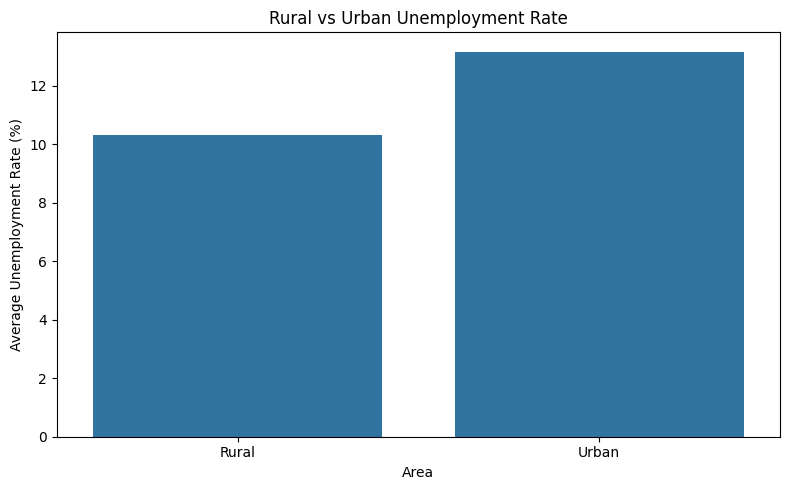

,Area,Estimated Unemployment Rate (%)
0,Rural,10.324791
1,Urban,13.166614


In [ ]:
#Rural vs Urban unemployment comparison
area_unemployment = (
    df.groupby('Area')[unemployment_col]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=area_unemployment,
    x='Area',
    y=unemployment_col
)

plt.title('Rural vs Urban Unemployment Rate')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')

plt.tight_layout()
plt.show()

display(area_unemployment)

COVID-19 Impact Analysis:


,Estimated Unemployment Rate (%)
Period,
Pre-COVID,9.509534
COVID Period,20.194342


Change in unemployment rate: 10.68 percentage points


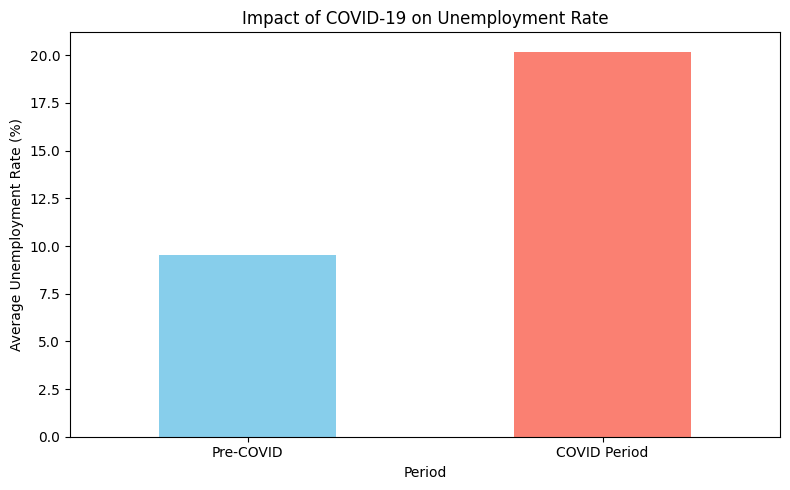

In [ ]:
#COVID-19 impact analysis
# Add year and month
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

# Define periods
df['Period'] = np.where(
    df['Date'] < '2020-03-01',
    'Pre-COVID',
    np.where(
        df['Date'] >= '2020-04-01',
        'COVID Period',
        'Transition'
    )
)

# Compare pre-COVID and COVID periods
covid_analysis = (
    df[df['Period'].isin(['Pre-COVID', 'COVID Period'])]
    .groupby('Period')[unemployment_col]
    .mean()
    .reindex(['Pre-COVID', 'COVID Period'])
)

print("COVID-19 Impact Analysis:")
display(covid_analysis)

# Calculate difference
difference = (
    covid_analysis['COVID Period'] -
    covid_analysis['Pre-COVID']
)

print("Change in unemployment rate:",
      round(difference, 2), "percentage points")

# Visualization
plt.figure(figsize=(8, 5))

covid_analysis.plot(
    kind='bar',
    color=['skyblue', 'salmon']
)

plt.title('Impact of COVID-19 on Unemployment Rate')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

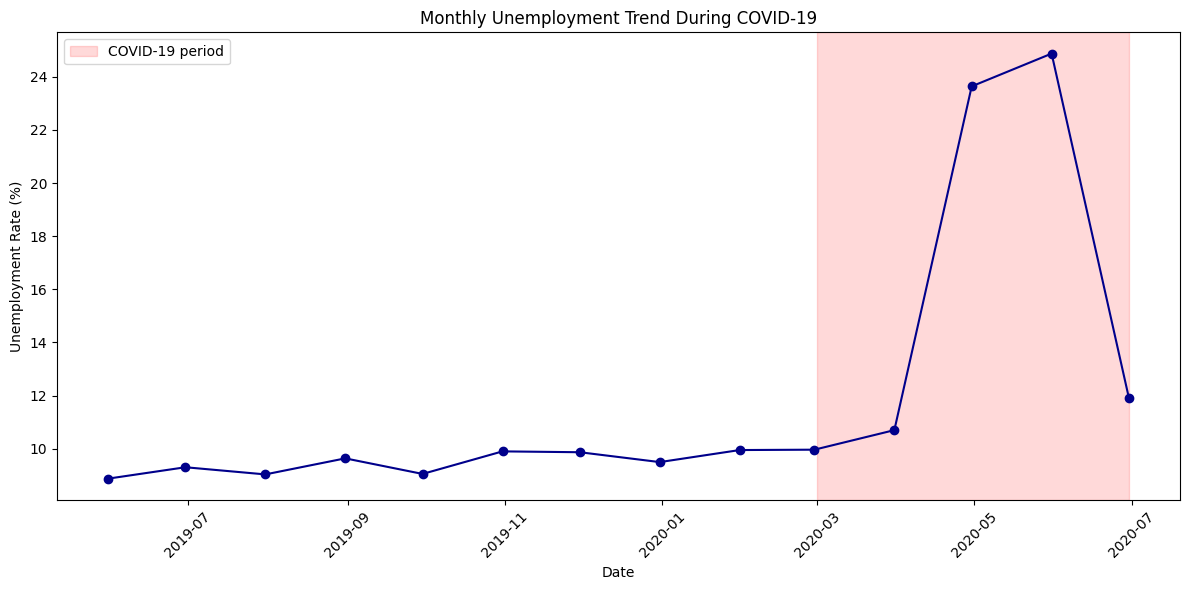

In [ ]:
#Monthly COVID-19 impact trend
covid_monthly = (
    df.groupby('Date')[unemployment_col]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    covid_monthly['Date'],
    covid_monthly[unemployment_col],
    marker='o',
    color='darkblue'
)

# Mark the lockdown period
plt.axvspan(
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2020-06-30'),
    color='red',
    alpha=0.15,
    label='COVID-19 period'
)

plt.title('Monthly Unemployment Trend During COVID-19')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

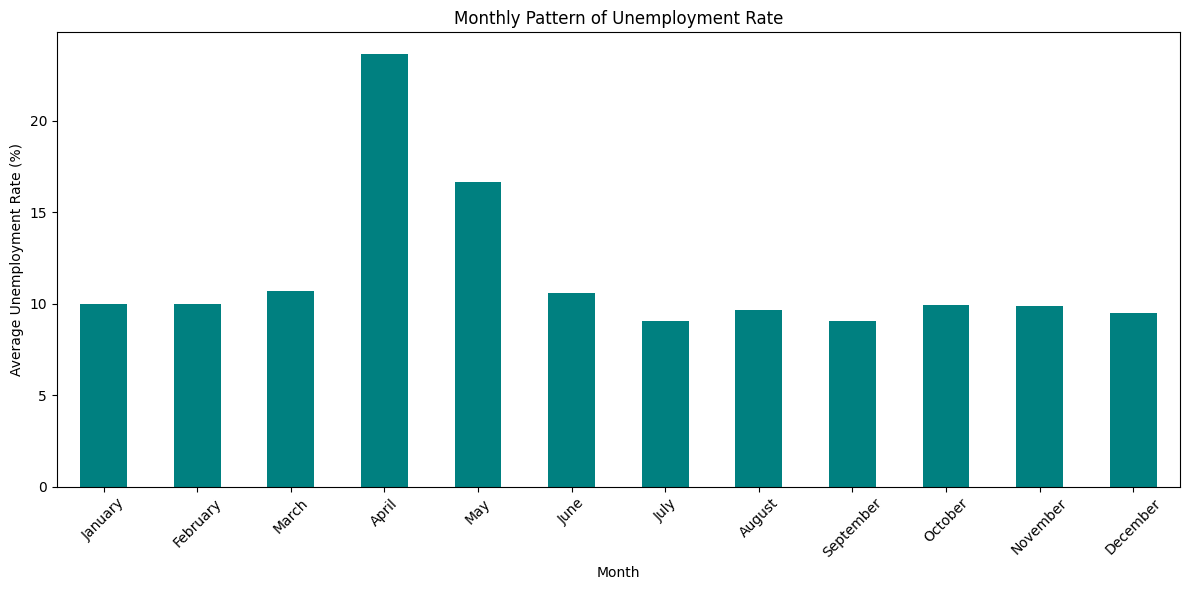

,Estimated Unemployment Rate (%)
Month_Name,
January,9.950755
February,9.964717
March,10.700577
April,23.641569
May,16.646190
June,10.553462
July,9.033889
August,9.637925
September,9.051731


In [ ]:
#Seasonal unemployment pattern
df['Month_Name'] = df['Date'].dt.month_name()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

seasonal_analysis = (
    df.groupby('Month_Name')[unemployment_col]
    .mean()
    .reindex(month_order)
    .dropna()
)

plt.figure(figsize=(12, 6))

seasonal_analysis.plot(
    kind='bar',
    color='teal'
)

plt.title('Monthly Pattern of Unemployment Rate')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(seasonal_analysis)

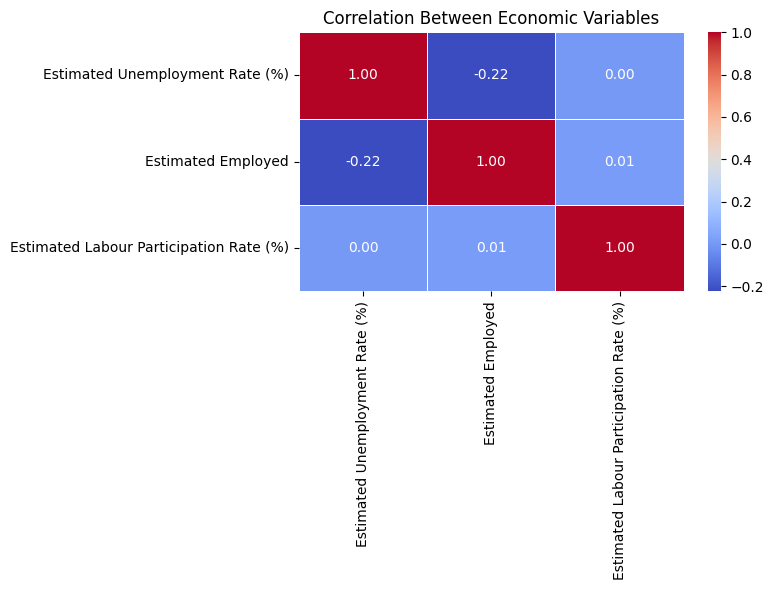

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


In [ ]:
#Correlation analysis
correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Economic Variables')
plt.tight_layout()
plt.show()

display(correlation)

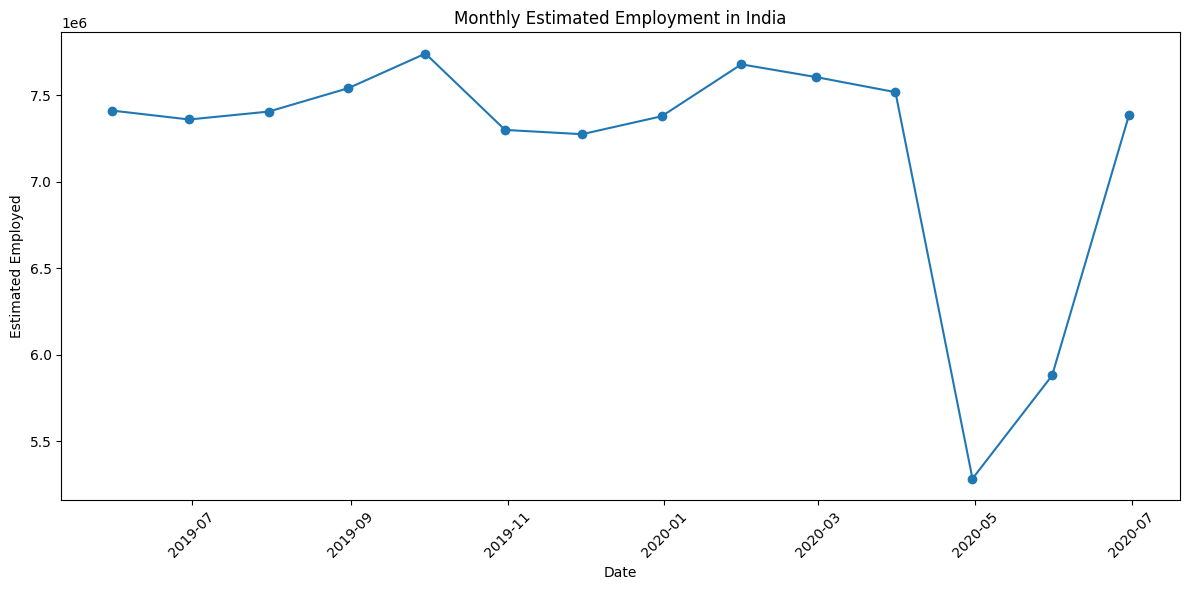

In [ ]:
# Employment and labour participation analysis
#Monthly average employment
monthly_employment = (
    df.groupby('Date')['Estimated Employed']
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_employment.index,
    monthly_employment.values,
    marker='o'
)

plt.title('Monthly Estimated Employment in India')
plt.xlabel('Date')
plt.ylabel('Estimated Employed')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

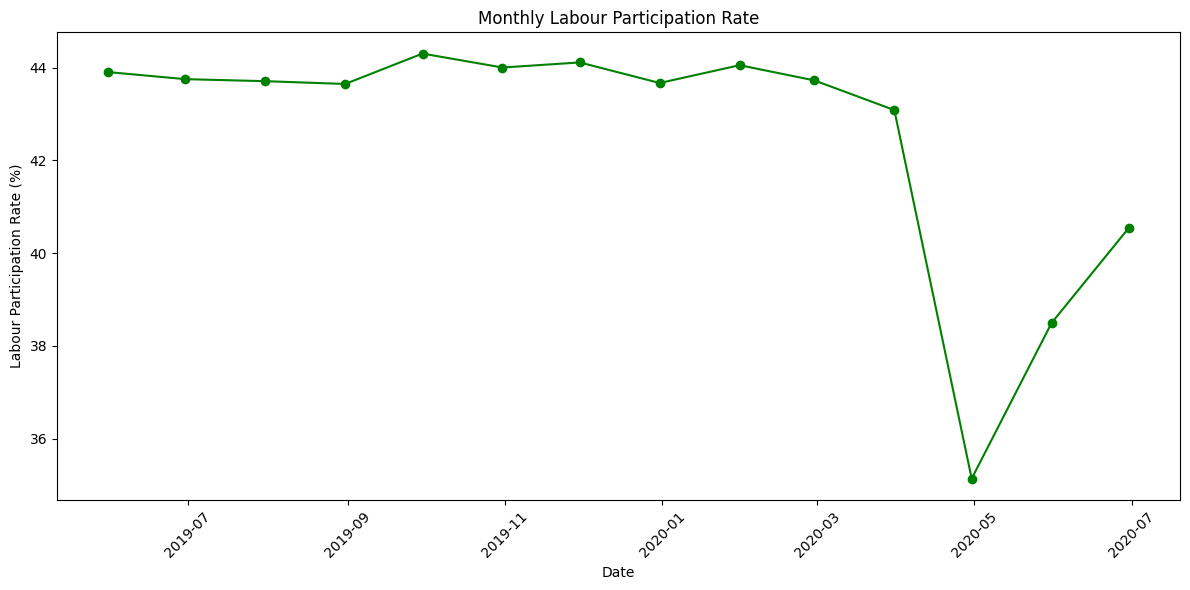

In [ ]:
# Labour participation rate
monthly_labour = (
    df.groupby('Date')['Estimated Labour Participation Rate (%)']
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_labour.index,
    monthly_labour.values,
    marker='o',
    color='green'
)

plt.title('Monthly Labour Participation Rate')
plt.xlabel('Date')
plt.ylabel('Labour Participation Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Identify highest unemployment month
highest_month = monthly_unemployment.loc[
    monthly_unemployment[unemployment_col].idxmax()
]

lowest_month = monthly_unemployment.loc[
    monthly_unemployment[unemployment_col].idxmin()
]

print("Highest Unemployment Month:")
print(highest_month)

print("\nLowest Unemployment Month:")
print(lowest_month)

Highest Unemployment Month:
Date                               2020-05-31 00:00:00
Estimated Unemployment Rate (%)              24.875294
Name: 12, dtype: object

Lowest Unemployment Month:
Date                               2019-05-31 00:00:00
Estimated Unemployment Rate (%)               8.874259
Name: 0, dtype: object


In [ ]:
#Generate final analytical report
print("=" * 55)
print("       UNEMPLOYMENT ANALYSIS REPORT - INDIA")
print("=" * 55)

print("\n1. Total observations:", len(df))

print("\n2. Average unemployment rate:",
      round(df[unemployment_col].mean(), 2), "%")

print("\n3. Highest unemployment rate:",
      round(df[unemployment_col].max(), 2), "%")

print("\n4. Lowest unemployment rate:",
      round(df[unemployment_col].min(), 2), "%")

print("\n5. Average rural and urban unemployment:")
print(area_unemployment.to_string(index=False))

print("\n6. COVID-19 impact:")
print(covid_analysis)

print("\n7. Highest unemployment region:")
print(state_unemployment.index[0],
      "-", round(state_unemployment.iloc[0], 2), "%")

print("\n8. Lowest unemployment region:")
print(state_unemployment.index[-1],
      "-", round(state_unemployment.iloc[-1], 2), "%")

print("\n9. Highest unemployment month:")
print(highest_month['Date'].strftime('%B %Y'))

print("\n10. Lowest unemployment month:")
print(lowest_month['Date'].strftime('%B %Y'))

print("\n" + "=" * 55)
print("              ANALYSIS COMPLETED")
print("=" * 55)

       UNEMPLOYMENT ANALYSIS REPORT - INDIA

1. Total observations: 740

2. Average unemployment rate: 11.79 %

3. Highest unemployment rate: 76.74 %

4. Lowest unemployment rate: 0.0 %

5. Average rural and urban unemployment:
 Area  Estimated Unemployment Rate (%)
Rural                        10.324791
Urban                        13.166614

6. COVID-19 impact:
Period
Pre-COVID        9.509534
COVID Period    20.194342
Name: Estimated Unemployment Rate (%), dtype: float64

7. Highest unemployment region:
Tripura - 28.35 %

8. Lowest unemployment region:
Meghalaya - 4.8 %

9. Highest unemployment month:
May 2020

10. Lowest unemployment month:
May 2019

              ANALYSIS COMPLETED
